# Week-43

- Why we change from WL-Palette to DRLN?
- Which node properties are better for our model in seal_directed? Here I want not only tht list (if we have it) but plot ideas.
- Why we use 1:1 instead of 2:1 like WLNM?
- Why precision has come down?
- Does the results vary a lot among the x10 runs?

- Generate document of figures and manuscript.
- GEnerate the predation matrix, to get sense of where we get wrong, and compare it to WLNM
- GEnerate figures grouped by ecosystem type.
---

- Extract what properties are more benefitial (use python library) importance of model features python
- Organize results
- Simple english: Summarize techniques, what we have found in each figure. Before spending a lot of time with the manuscript writting up.
- How to compare WLNM to SEAL

WLNM:
- Add node properties: mass of consumer and mass of resource (focal species)
- Add link feature:
    - Ecosystem type,
    - BodyMass ratio (maybe workss well to acuatic one or terrerstial), maybe tag the Bodymass ratio to the ecosystem type
    - Both

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Loading and validating the four result sets...
[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.

=== Input and protocol audit ===


,Method,Source,Food webs,Raw runs,Runs/web,Aggregation,Test negatives:positives,Target train ratio,Achieved ratio recorded,Threshold,Notes
0,WLNM original,result_wlnm_original_100x290_train10-90_thresh...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
1,WLNM directed-negative,result_wlnm_dir_neg_roleonly_trophicv2_100x290...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
2,SEAL original,src/python/seal_original_gpu/data/result_seal_...,290,2900,10,Mean across repeats,1:1,90%,50.00–94.74% (median 90.23%),0.50,Balanced held-out positives/negatives; CUDA ca...
3,SEAL directed,src/python/seal_directed/data/result_seal_dire...,290,2900,10,Mean across repeats,1:1,90%,90.00–94.74% (median 90.13%),0.50,Balanced held-out positives/negatives; role-po...



=== WLNM raw-run counts for the five common metrics ===


,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns,Method
0,ROC-AUC,290,100,100.0,100,WLNM original
1,PR-AUC,290,100,100.0,100,WLNM original
2,F1,290,100,100.0,100,WLNM original
3,Precision,290,100,100.0,100,WLNM original
4,Recall,290,100,100.0,100,WLNM original
5,ROC-AUC,290,100,100.0,100,WLNM directed-negative
6,PR-AUC,290,100,100.0,100,WLNM directed-negative
7,F1,290,100,100.0,100,WLNM directed-negative
8,Precision,290,100,100.0,100,WLNM directed-negative
9,Recall,290,100,100.0,100,WLNM directed-negative



=== Food-web-level descriptive medians ===


Method,WLNM original,WLNM directed-negative,SEAL original,SEAL directed
Metric,,,,
ROC-AUC,0.8306,0.9102,0.8152,0.9148
PR-AUC,0.6032,0.5475,0.8099,0.9153
F1,0.6591,0.7201,0.7487,0.8396
Precision,0.7180,0.9507,0.7174,0.8335
Recall,0.6372,0.6079,0.8064,0.8556



[PASS] Generated 20 boxplots (4 methods × 5 metrics).


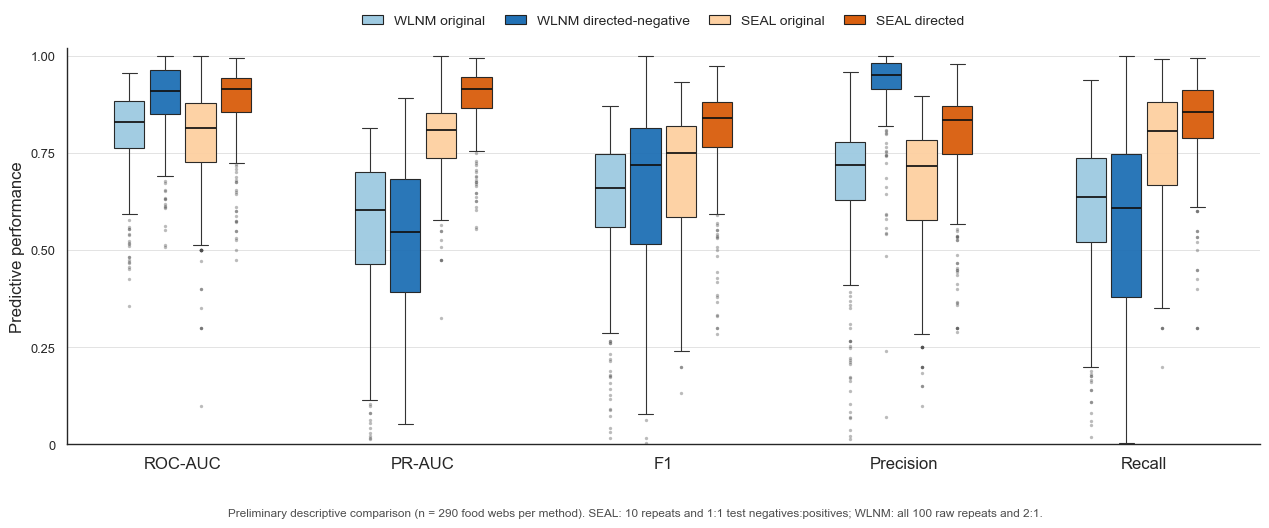

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Configuration
# ============================================================

def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(f"Repository root not found from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
TRAIN_RATIO = 90
THRESHOLD = 0.50
N_WEBS = 290
WLNM_RUNS = 100
MIN_RETAINED = 25
RETENTION = "tukey_iqr_1p5_min25runs_threshold0p50_v1"

WLNM_ROOTS = {
    "WLNM_original": REPO_ROOT / "src/matlab/data/result_wlnm_original_100x290_train10-90_thresh0p50_Apocrita_20260916_221905",
    "WLNM_dir_neg": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848",
}
SEAL_ORIGINAL_10X_ROOT = REPO_ROOT / "src/python/seal_original_gpu/data/result_seal_original_10x290_9736688d_20261019"
SEAL_DIRECTED_10X_ROOT = REPO_ROOT / "src/python/seal_directed/data/result_seal_directed_10x290_220d0a21_20261014"
SEAL_CONFIG = {
    "SEAL_original": {
        "results": SEAL_ORIGINAL_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_ORIGINAL_10X_ROOT / "runs",
        "log_pattern": "*/experiment_*_seed_*/terminal.log",
        "validation": SEAL_ORIGINAL_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "distinct_numeric_seeds": 10,
            "nonfinite_predictive_metrics": 0,
            "core_logic_policy": "exact_historical_behavior_no_corrections",
        },
        "device_column": False,
        "pattern": "*_results_SEAL.csv",
        "version": "SEAL_undirected",
        "repeats": 10,
        "seeds": set(range(12345, 12355)),
        "fallbacks": 0,
    },
    "SEAL_directed": {
        "results": SEAL_DIRECTED_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_DIRECTED_10X_ROOT / "task_logs",
        "log_pattern": "**/*.log",
        "validation": SEAL_DIRECTED_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "unique_seeds": N_WEBS * 10,
            "fallback_runs": 80,
        },
        "device_column": True,
        "pattern": "*_results_SEAL_directed.csv",
        "version": "SEAL_directed",
        "repeats": 10,
        "seeds": set(range(12345, 12345 + N_WEBS * 10)),
        "fallbacks": 80,
    },
}
METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
]
METRICS = [x for x, _ in METRIC_SPECS]
METRIC_LABELS = dict(METRIC_SPECS)
METHOD_ORDER = ["WLNM_original", "WLNM_dir_neg", "SEAL_original", "SEAL_directed"]
METHOD_LABELS = {
    "WLNM_original": "WLNM original",
    "WLNM_dir_neg": "WLNM directed-negative",
    "SEAL_original": "SEAL original",
    "SEAL_directed": "SEAL directed",
}
PALETTE = {
    "WLNM_original": "#9ECAE1",
    "WLNM_dir_neg": "#2171B5",
    "SEAL_original": "#FDD0A2",
    "SEAL_directed": "#D95F0E",
}


# ============================================================
# Loaders and validation
# ============================================================

def fw_key(value):
    text = Path(str(value)).stem.strip()
    text = re.sub(r"_tax_mass_results_SEAL(?:_directed)?$", "", text, flags=re.I)
    text = re.sub(r"_tax_mass_results_random_wlnm_(?:original|dir_neg)$", "", text, flags=re.I)
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text.casefold()).split())


def validate_values(frame, label):
    values = frame[METRICS].apply(pd.to_numeric, errors="coerce")
    if values.isna().any().any():
        raise ValueError(f"{label}: missing or non-numeric metric values")
    array = values.to_numpy(float)
    if not np.isfinite(array).all() or ((array < 0) | (array > 1)).any():
        raise ValueError(f"{label}: metric values must be finite and within [0, 1]")


def validate_keys(frame, source_col, label):
    collisions = (
        frame[["FW_KEY", source_col]].drop_duplicates()
        .groupby("FW_KEY")[source_col].nunique()
    )
    if (collisions > 1).any():
        raise ValueError(f"{label}: normalized food-web name collision")
    if frame["FW_KEY"].nunique() != N_WEBS:
        raise ValueError(f"{label}: expected {N_WEBS} food webs")


def validate_wlnm_raw(root):
    files = sorted((root / "prediction_scores_logs").glob("*.csv"))
    if len(files) != N_WEBS:
        raise ValueError(f"{root.name}: expected {N_WEBS} raw CSV files")
    ratios = []
    total_rows = 0
    usecols = ["TrainRatio", "TestTP", "TestFP", "TestFN", "TestTN"]
    for path in files:
        data = pd.read_csv(path, usecols=usecols)
        data = data[np.isclose(data["TrainRatio"], TRAIN_RATIO)]
        if len(data) != WLNM_RUNS:
            raise ValueError(f"{path.name}: expected {WLNM_RUNS} train-90 runs")
        positives = data["TestTP"] + data["TestFN"]
        negatives = data["TestFP"] + data["TestTN"]
        if (positives <= 0).any():
            raise ValueError(f"{path.name}: invalid test-positive count")
        ratios.extend((negatives / positives).to_numpy(float))
        total_rows += len(data)
    ratios = np.asarray(ratios)
    if not np.allclose(ratios, 2.0):
        raise ValueError(f"{root.name}: test negative:positive ratio is not 2:1")
    return total_rows


def load_wlnm(method):
    root = WLNM_ROOTS[method]
    data = load_raw_predictive_compat(
        root,
        method,
        METRIC_SPECS,
        WLNM_RUNS,
        WLNM_RUNS,
        train_ratios=[TRAIN_RATIO],
    )
    data["FW_KEY"] = data["Foodweb"].map(fw_key)
    validate_keys(data, "Foodweb", method)
    if data.duplicated(["FW_KEY", "Metric"]).any():
        raise ValueError(f"{method}: duplicate food-web/metric rows")
    wide = (
        data.pivot(
            index="FW_KEY",
            columns="Metric",
            values="MeanAfterTukey",
        )
        .rename_axis(None, axis=1)
        .reset_index()
    )
    validate_values(wide, method)
    wide["Method"] = method
    raw_rows = validate_wlnm_raw(root)
    retention = data.groupby("Metric", as_index=False).agg(
        FoodWebs=("FW_KEY", "nunique"),
        MinimumRetainedRuns=("RetainedRunsAfterTukey", "min"),
        MedianRetainedRuns=("RetainedRunsAfterTukey", "median"),
        MaximumRetainedRuns=("RetainedRunsAfterTukey", "max"),
    )
    retention["Method"] = METHOD_LABELS[method]
    retention["Metric"] = retention["Metric"].map(METRIC_LABELS)
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": root.name,
        "Food webs": N_WEBS,
        "Raw runs": raw_rows,
        "Runs/web": "100",
        "Aggregation": "Mean across all raw runs; no Tukey filtering",
        "Test negatives:positives": "2:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": "90% label",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": "All 100 raw runs included",
    }
    return wide, audit, retention

def load_seal(method, config):
    validation = None
    if validation_path := config.get("validation"):
        validation = json.loads(validation_path.read_text())
        expected_validation = config["validation_expected"]
        observed_validation = {
            key: validation.get(key) for key in expected_validation
        }
        if observed_validation != expected_validation:
            raise ValueError(
                f"{method}: unexpected campaign validation summary: "
                f"{observed_validation}"
            )
    files = sorted(config["results"].glob(config["pattern"]))
    if len(files) != N_WEBS:
        raise ValueError(f"{method}: expected {N_WEBS} result CSVs, found {len(files)}")
    frames = []
    required = set(METRICS) | {"Version", "TrainRatio", "ExperimentID", "Seed", "Threshold"}
    if config.get("device_column", False):
        required.add("Device")
    for path in files:
        data = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        if missing := required.difference(data.columns):
            raise ValueError(f"{path.name}: missing {sorted(missing)}")
        source_foodweb = re.sub(
            r"_tax_mass_results_SEAL(?:_directed)?\.csv$",
            "",
            path.name,
            flags=re.I,
        )
        data = data.assign(
            SourceFoodweb=source_foodweb,
            FW_KEY=fw_key(source_foodweb),
        )
        frames.append(data)
    raw = pd.concat(frames, ignore_index=True)
    validate_keys(raw, "SourceFoodweb", method)
    if config.get("device_column", False):
        if "Device" not in raw or set(raw["Device"].unique()) != {"cuda:0"}:
            raise ValueError(f"{method}: expected every validated run to use cuda:0")
    if set(raw["Version"].unique()) != {config["version"]}:
        raise ValueError(f"{method}: unexpected Version")
    if not np.allclose(raw["Threshold"], THRESHOLD):
        raise ValueError(f"{method}: unexpected threshold")
    if set(raw["Seed"].astype(int)) != config["seeds"] or set(raw["ExperimentID"].astype(int)) != set(range(1, config["repeats"] + 1)):
        raise ValueError(f"{method}: unexpected seeds or ExperimentID values")
    if set(raw.groupby("FW_KEY").size()) != {config["repeats"]}:
        raise ValueError(f"{method}: unexpected repeats per food web")
    if raw.duplicated(["FW_KEY", "ExperimentID"]).any():
        raise ValueError(f"{method}: duplicate food-web/experiment rows")
    validate_values(raw, method)

    log_files = sorted(config["logs"].glob(config["log_pattern"]))
    if len(log_files) != len(raw):
        raise ValueError(f"{method}: expected {len(raw)} terminal logs, found {len(log_files)}")
    fallback_text = "role-constrained negative pool too small; falling back to all directed unknown links"
    fallbacks = sum(fallback_text in path.read_text(errors="replace") for path in log_files)
    if fallbacks != config["fallbacks"]:
        raise ValueError(f"{method}: expected {config['fallbacks']} fallbacks, found {fallbacks}")

    wide = raw.groupby("FW_KEY", as_index=False)[METRICS].mean()
    validate_values(wide, f"{method} means")
    wide["Method"] = method
    ratio_min, ratio_median, ratio_max = raw.TrainRatio.min(), raw.TrainRatio.median(), raw.TrainRatio.max()
    note = "Balanced held-out positives/negatives"
    if method == "SEAL_directed":
        note += f"; role-pool fallback in {fallbacks}/{len(raw)} runs"
    if validation is not None:
        note += "; CUDA campaign VALIDATION_OK"
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": str(config["results"].relative_to(REPO_ROOT)),
        "Food webs": N_WEBS,
        "Raw runs": len(raw),
        "Runs/web": str(config["repeats"]),
        "Aggregation": "Mean across repeats",
        "Test negatives:positives": "1:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": f"{ratio_min:.2f}–{ratio_max:.2f}% (median {ratio_median:.2f}%)",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": note,
    }
    return wide, audit


# ============================================================
# Build the matched comparison table
# ============================================================

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Loading and validating the four result sets...")

wlnm_original, audit_wo, retention_wo = load_wlnm("WLNM_original")
wlnm_dir_neg, audit_wd, retention_wd = load_wlnm("WLNM_dir_neg")
seal_original, audit_so = load_seal("SEAL_original", SEAL_CONFIG["SEAL_original"])
seal_directed, audit_sd = load_seal("SEAL_directed", SEAL_CONFIG["SEAL_directed"])
frames = {
    "WLNM_original": wlnm_original,
    "WLNM_dir_neg": wlnm_dir_neg,
    "SEAL_original": seal_original,
    "SEAL_directed": seal_directed,
}
key_sets = {method: set(frame.FW_KEY) for method, frame in frames.items()}
common = set.intersection(*key_sets.values())
union = set.union(*key_sets.values())
if len(common) != N_WEBS or len(union) != N_WEBS:
    details = {method: {"missing": sorted(union - keys)[:10], "unpaired": sorted(keys - common)[:10]} for method, keys in key_sets.items()}
    raise ValueError(f"Food-web matching failed: {details}")

comparison_wide = pd.concat([frames[m] for m in METHOD_ORDER], ignore_index=True)[["FW_KEY", "Method", *METRICS]]
if comparison_wide.shape != (1160, 7) or comparison_wide.duplicated(["FW_KEY", "Method"]).any():
    raise ValueError(f"Invalid wide table: shape={comparison_wide.shape}")
validate_values(comparison_wide, "combined comparison")
comparison_long = comparison_wide.melt(
    id_vars=["FW_KEY", "Method"], value_vars=METRICS,
    var_name="Metric", value_name="Value",
)
comparison_long["MethodLabel"] = comparison_long.Method.map(METHOD_LABELS)
comparison_long["MetricLabel"] = comparison_long.Metric.map(METRIC_LABELS)
if len(comparison_long) != 5800 or comparison_long.Value.isna().any():
    raise ValueError(f"Invalid long table: rows={len(comparison_long)}")
print("[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.")


# ============================================================
# Audit and descriptive summaries
# ============================================================

audit_table = pd.DataFrame([audit_wo, audit_wd, audit_so, audit_sd])
print("\n=== Input and protocol audit ===")
display(audit_table)

retention_table = pd.concat([retention_wo, retention_wd], ignore_index=True)
metric_order = [label for _, label in METRIC_SPECS]
retention_table["Metric"] = pd.Categorical(retention_table.Metric, metric_order, ordered=True)
retention_table["Method"] = pd.Categorical(
    retention_table.Method,
    [METHOD_LABELS[m] for m in METHOD_ORDER[:2]],
    ordered=True,
)
retention_table = retention_table.sort_values(["Method", "Metric"]).reset_index(drop=True)
print("\n=== WLNM raw-run counts for the five common metrics ===")
display(retention_table)

median_table = (
    comparison_long.groupby(["Metric", "Method"], observed=True).Value.median()
    .unstack("Method").reindex(index=METRICS, columns=METHOD_ORDER)
    .rename(index=METRIC_LABELS, columns=METHOD_LABELS).round(4)
)
print("\n=== Food-web-level descriptive medians ===")
display(median_table)

# print("\n[CAUTION] Preliminary descriptive comparison only. SEAL uses 10 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.")
# print("[CAUTION] 'SEAL directed' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.")


# ============================================================
# Grouped boxplots (one value per food web and method)
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=1.05)
fig, ax = plt.subplots(figsize=(12.8, 5.8))
centers = np.arange(len(METRICS), dtype=float) * 1.35 + 1.0
offsets = {"WLNM_original": -0.30, "WLNM_dir_neg": -0.10, "SEAL_original": 0.10, "SEAL_directed": 0.30}
box_count = 0
for method in METHOD_ORDER:
    datasets, positions = [], []
    for i, metric in enumerate(METRICS):
        values = comparison_long.loc[
            comparison_long.Method.eq(method) & comparison_long.Metric.eq(metric), "Value"
        ].to_numpy(float)
        if len(values) != N_WEBS:
            raise ValueError(f"{method}/{metric}: expected {N_WEBS} values")
        datasets.append(values)
        positions.append(centers[i] + offsets[method])
    artists = ax.boxplot(
        datasets, positions=positions, widths=0.17, patch_artist=True,
        manage_ticks=False, showfliers=True, whis=1.5,
        boxprops={"facecolor": PALETTE[method], "edgecolor": "#222222", "linewidth": 0.8, "alpha": 0.96},
        medianprops={"color": "#111111", "linewidth": 1.25},
        whiskerprops={"color": "#333333", "linewidth": 0.8},
        capprops={"color": "#333333", "linewidth": 0.8},
        flierprops={"marker": "o", "markersize": 2.4, "markerfacecolor": "#4D4D4D", "markeredgecolor": "none", "alpha": 0.38},
    )
    box_count += len(artists["boxes"])
if box_count != 20:
    raise RuntimeError(f"Expected 20 box artists, created {box_count}")

handles = [Patch(facecolor=PALETTE[m], edgecolor="#222222", linewidth=0.8, label=METHOD_LABELS[m]) for m in METHOD_ORDER]
ax.set_xlim(centers[0] - 0.65, centers[-1] + 0.65)
ax.set_ylim(0, 1.02)
ax.set_xticks(centers, [METRIC_LABELS[m] for m in METRICS], fontsize=12)
ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00], ["0", "0.25", "0.50", "0.75", "1.00"])
ax.set_ylabel("Predictive performance", fontsize=12)
ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False, fontsize=10, columnspacing=1.4, handlelength=1.5)
sns.despine(ax=ax)
fig.text(
    0.5, 0.015,
    "Preliminary descriptive comparison (n = 290 food webs per method). SEAL: 10 repeats and 1:1 test negatives:positives; WLNM: all 100 raw repeats and 2:1.",
    ha="center", va="bottom", fontsize=8.5, color="#4D4D4D",
)
fig.tight_layout(rect=(0, 0.07, 1, 0.92))
print(f"\n[PASS] Generated {box_count} boxplots (4 methods × 5 metrics).")
plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Loading and validating the four result sets...
[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.

=== Input and protocol audit ===


,Method,Source,Food webs,Raw runs,Runs/web,Aggregation,Test negatives:positives,Target train ratio,Achieved ratio recorded,Threshold,Notes
0,WLNM original,result_wlnm_original_100x290_train10-90_thresh...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
1,WLNM directed-negative,result_wlnm_dir_neg_roleonly_trophicv2_100x290...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
2,SEAL original,src/python/seal_original_gpu/data/result_seal_...,290,2900,10,Mean across repeats,1:1,90%,50.00–94.74% (median 90.23%),0.50,Balanced held-out positives/negatives; CUDA ca...
3,SEAL directed,src/python/seal_directed/data/result_seal_dire...,290,2900,10,Mean across repeats,1:1,90%,90.00–94.74% (median 90.13%),0.50,Balanced held-out positives/negatives; role-po...



=== WLNM raw-run counts for the five common metrics ===


,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns,Method
0,ROC-AUC,290,100,100.0,100,WLNM original
1,PR-AUC,290,100,100.0,100,WLNM original
2,F1,290,100,100.0,100,WLNM original
3,Precision,290,100,100.0,100,WLNM original
4,Recall,290,100,100.0,100,WLNM original
5,ROC-AUC,290,100,100.0,100,WLNM directed-negative
6,PR-AUC,290,100,100.0,100,WLNM directed-negative
7,F1,290,100,100.0,100,WLNM directed-negative
8,Precision,290,100,100.0,100,WLNM directed-negative
9,Recall,290,100,100.0,100,WLNM directed-negative



=== Food-web-level descriptive medians ===


Method,WLNM original,WLNM directed-negative,SEAL original,SEAL directed
Metric,,,,
ROC-AUC,0.8306,0.9102,0.8152,0.9148
PR-AUC,0.6032,0.5475,0.8099,0.9153
F1,0.6591,0.7201,0.7487,0.8396
Precision,0.7180,0.9507,0.7174,0.8335
Recall,0.6372,0.6079,0.8064,0.8556



=== Food webs by ecosystem ===


,EcosystemType,FoodWebs
0,marine,134
1,lakes,55
2,streams,28
3,terrestrial aboveground,21
4,terrestrial belowground,52



[PASS] Marine: generated 20 boxplots from 134 food webs per method.


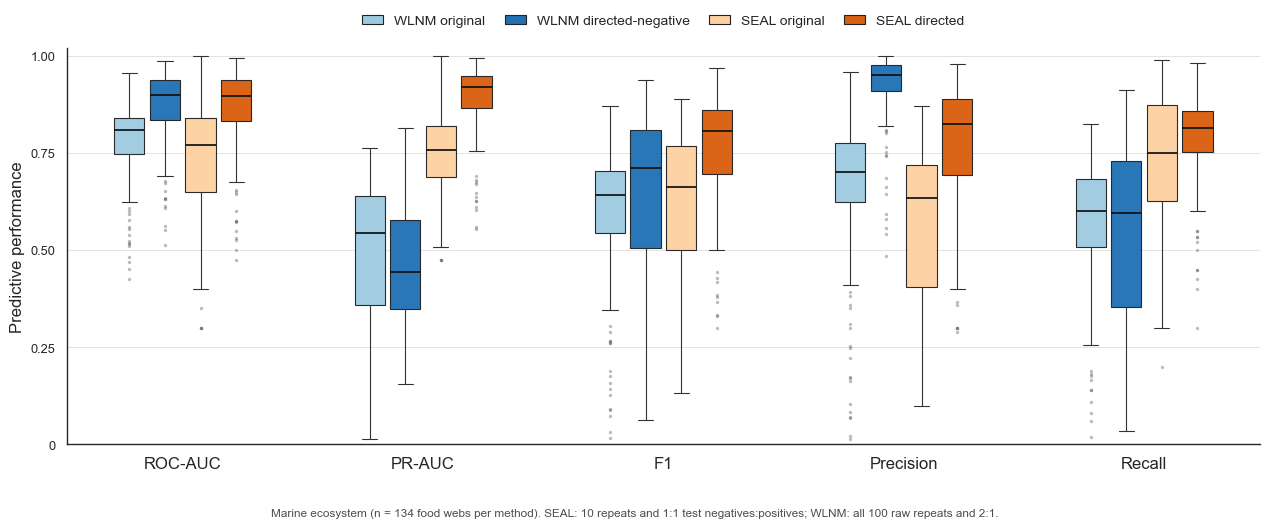


[PASS] Lakes: generated 20 boxplots from 55 food webs per method.


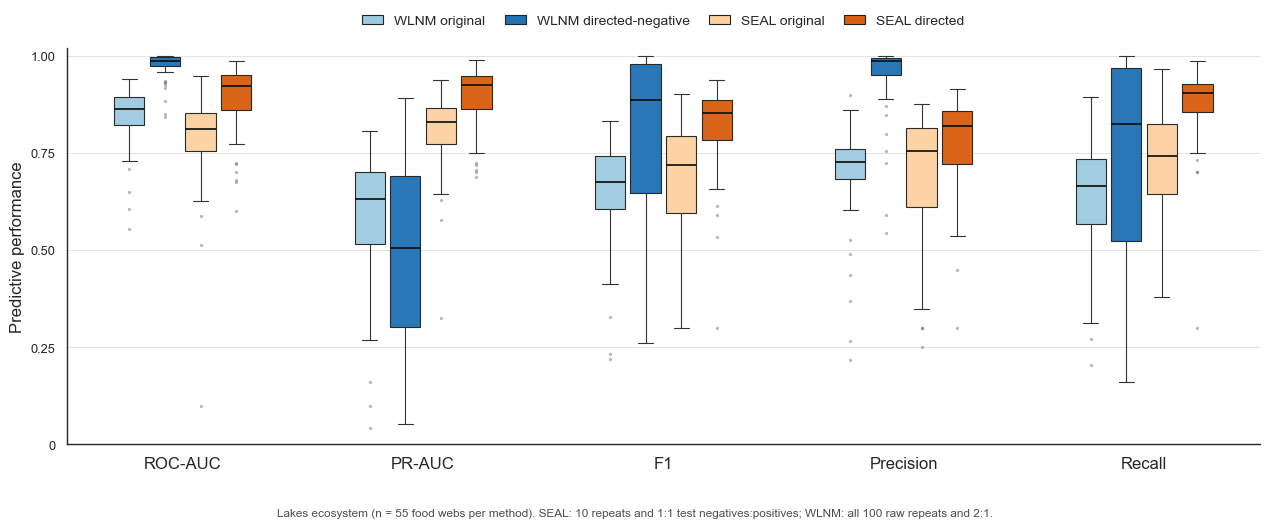


[PASS] Streams: generated 20 boxplots from 28 food webs per method.


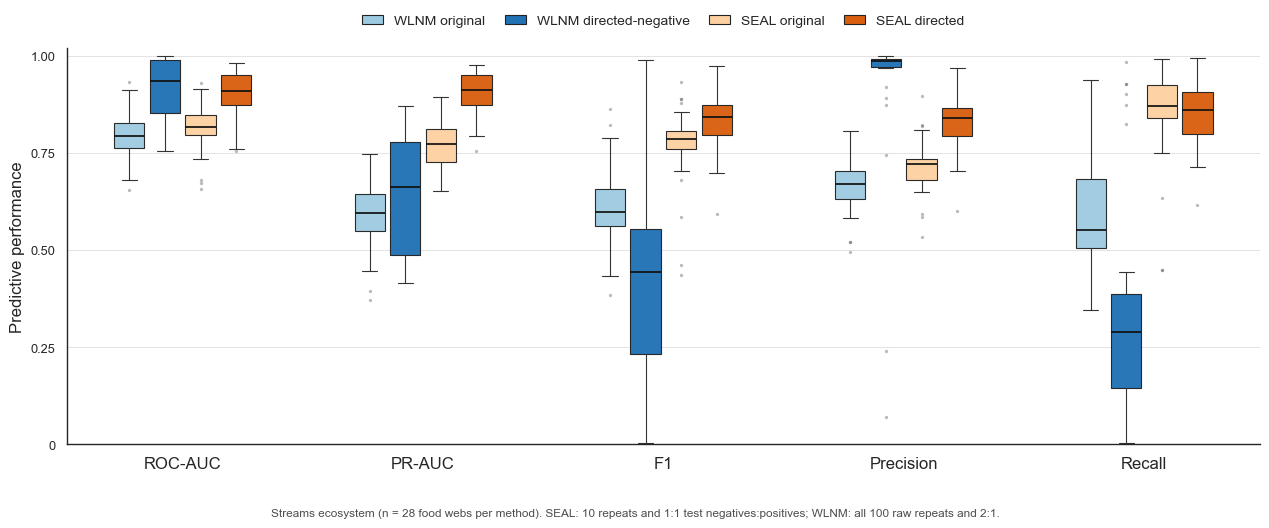


[PASS] Terrestrial aboveground: generated 20 boxplots from 21 food webs per method.


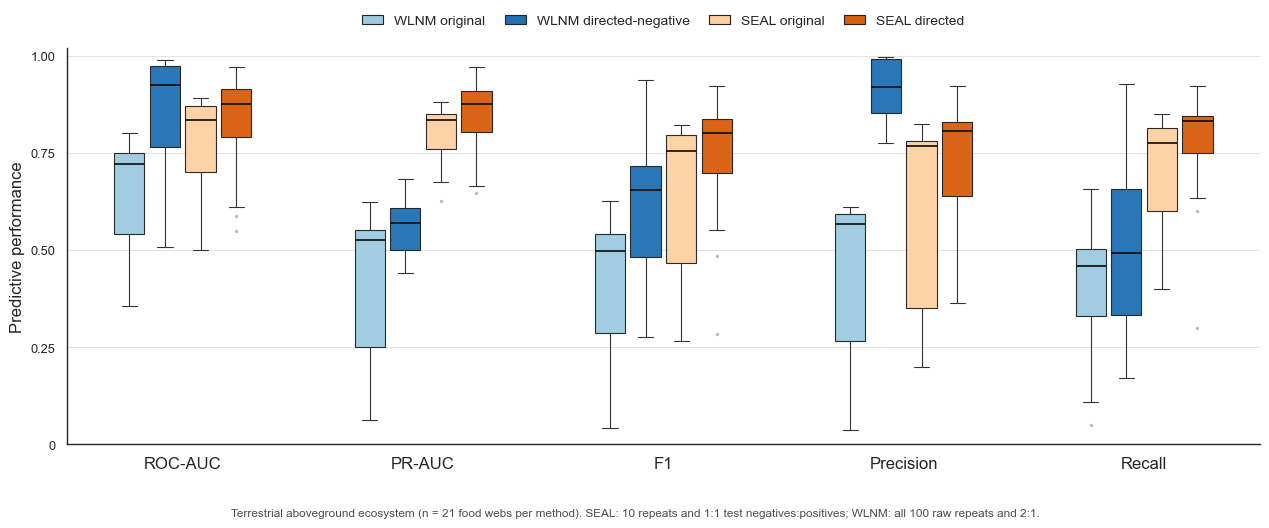


[PASS] Terrestrial belowground: generated 20 boxplots from 52 food webs per method.


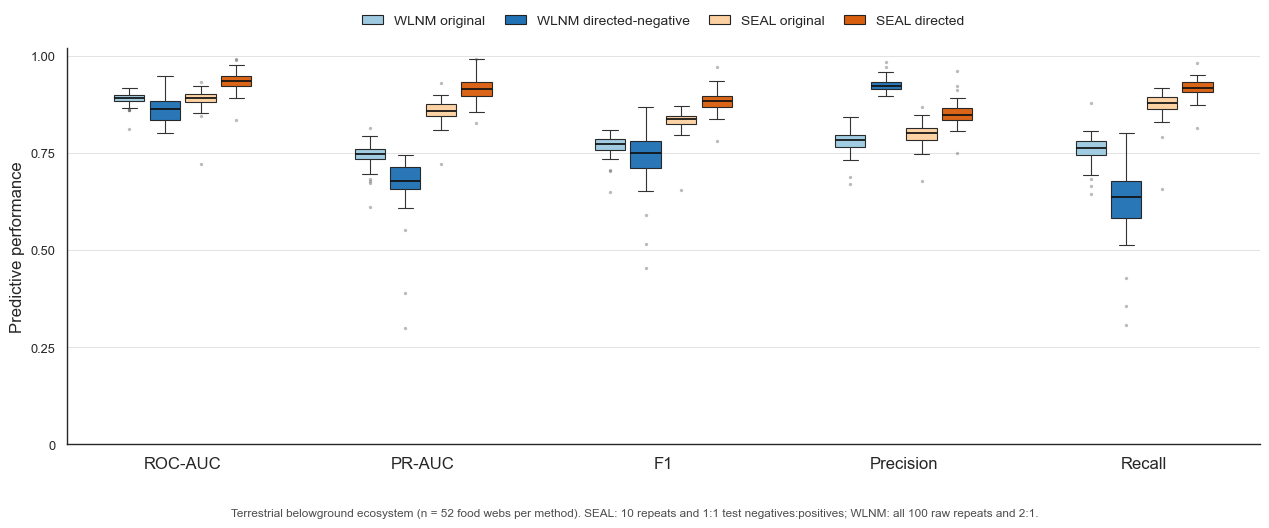


[PASS] Generated five independent ecosystem figures.


In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Configuration
# ============================================================

def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(f"Repository root not found from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
TRAIN_RATIO = 90
THRESHOLD = 0.50
N_WEBS = 290
WLNM_RUNS = 100
MIN_RETAINED = 25
RETENTION = "tukey_iqr_1p5_min25runs_threshold0p50_v1"

WLNM_ROOTS = {
    "WLNM_original": REPO_ROOT / "src/matlab/data/result_wlnm_original_100x290_train10-90_thresh0p50_Apocrita_20260916_221905",
    "WLNM_dir_neg": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848",
}
SEAL_ORIGINAL_10X_ROOT = REPO_ROOT / "src/python/seal_original_gpu/data/result_seal_original_10x290_9736688d_20261019"
SEAL_DIRECTED_10X_ROOT = REPO_ROOT / "src/python/seal_directed/data/result_seal_directed_10x290_220d0a21_20261014"
SEAL_CONFIG = {
    "SEAL_original": {
        "results": SEAL_ORIGINAL_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_ORIGINAL_10X_ROOT / "runs",
        "log_pattern": "*/experiment_*_seed_*/terminal.log",
        "validation": SEAL_ORIGINAL_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "distinct_numeric_seeds": 10,
            "nonfinite_predictive_metrics": 0,
            "core_logic_policy": "exact_historical_behavior_no_corrections",
        },
        "device_column": False,
        "pattern": "*_results_SEAL.csv",
        "version": "SEAL_undirected",
        "repeats": 10,
        "seeds": set(range(12345, 12355)),
        "fallbacks": 0,
    },
    "SEAL_directed": {
        "results": SEAL_DIRECTED_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_DIRECTED_10X_ROOT / "task_logs",
        "log_pattern": "**/*.log",
        "validation": SEAL_DIRECTED_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "unique_seeds": N_WEBS * 10,
            "fallback_runs": 80,
        },
        "device_column": True,
        "pattern": "*_results_SEAL_directed.csv",
        "version": "SEAL_directed",
        "repeats": 10,
        "seeds": set(range(12345, 12345 + N_WEBS * 10)),
        "fallbacks": 80,
    },
}
METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
]
METRICS = [x for x, _ in METRIC_SPECS]
METRIC_LABELS = dict(METRIC_SPECS)
METHOD_ORDER = ["WLNM_original", "WLNM_dir_neg", "SEAL_original", "SEAL_directed"]
METHOD_LABELS = {
    "WLNM_original": "WLNM original",
    "WLNM_dir_neg": "WLNM directed-negative",
    "SEAL_original": "SEAL original",
    "SEAL_directed": "SEAL directed",
}
PALETTE = {
    "WLNM_original": "#9ECAE1",
    "WLNM_dir_neg": "#2171B5",
    "SEAL_original": "#FDD0A2",
    "SEAL_directed": "#D95F0E",
}


# ============================================================
# Loaders and validation
# ============================================================

def fw_key(value):
    text = Path(str(value)).stem.strip()
    text = re.sub(r"_tax_mass_results_SEAL(?:_directed)?$", "", text, flags=re.I)
    text = re.sub(r"_tax_mass_results_random_wlnm_(?:original|dir_neg)$", "", text, flags=re.I)
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text.casefold()).split())


def validate_values(frame, label):
    values = frame[METRICS].apply(pd.to_numeric, errors="coerce")
    if values.isna().any().any():
        raise ValueError(f"{label}: missing or non-numeric metric values")
    array = values.to_numpy(float)
    if not np.isfinite(array).all() or ((array < 0) | (array > 1)).any():
        raise ValueError(f"{label}: metric values must be finite and within [0, 1]")


def validate_keys(frame, source_col, label):
    collisions = (
        frame[["FW_KEY", source_col]].drop_duplicates()
        .groupby("FW_KEY")[source_col].nunique()
    )
    if (collisions > 1).any():
        raise ValueError(f"{label}: normalized food-web name collision")
    if frame["FW_KEY"].nunique() != N_WEBS:
        raise ValueError(f"{label}: expected {N_WEBS} food webs")


def validate_wlnm_raw(root):
    files = sorted((root / "prediction_scores_logs").glob("*.csv"))
    if len(files) != N_WEBS:
        raise ValueError(f"{root.name}: expected {N_WEBS} raw CSV files")
    ratios = []
    total_rows = 0
    usecols = ["TrainRatio", "TestTP", "TestFP", "TestFN", "TestTN"]
    for path in files:
        data = pd.read_csv(path, usecols=usecols)
        data = data[np.isclose(data["TrainRatio"], TRAIN_RATIO)]
        if len(data) != WLNM_RUNS:
            raise ValueError(f"{path.name}: expected {WLNM_RUNS} train-90 runs")
        positives = data["TestTP"] + data["TestFN"]
        negatives = data["TestFP"] + data["TestTN"]
        if (positives <= 0).any():
            raise ValueError(f"{path.name}: invalid test-positive count")
        ratios.extend((negatives / positives).to_numpy(float))
        total_rows += len(data)
    ratios = np.asarray(ratios)
    if not np.allclose(ratios, 2.0):
        raise ValueError(f"{root.name}: test negative:positive ratio is not 2:1")
    return total_rows


def load_wlnm(method):
    root = WLNM_ROOTS[method]
    data = load_raw_predictive_compat(
        root,
        method,
        METRIC_SPECS,
        WLNM_RUNS,
        WLNM_RUNS,
        train_ratios=[TRAIN_RATIO],
    )
    data["FW_KEY"] = data["Foodweb"].map(fw_key)
    validate_keys(data, "Foodweb", method)
    if data.duplicated(["FW_KEY", "Metric"]).any():
        raise ValueError(f"{method}: duplicate food-web/metric rows")
    wide = (
        data.pivot(
            index="FW_KEY",
            columns="Metric",
            values="MeanAfterTukey",
        )
        .rename_axis(None, axis=1)
        .reset_index()
    )
    validate_values(wide, method)
    wide["Method"] = method
    raw_rows = validate_wlnm_raw(root)
    retention = data.groupby("Metric", as_index=False).agg(
        FoodWebs=("FW_KEY", "nunique"),
        MinimumRetainedRuns=("RetainedRunsAfterTukey", "min"),
        MedianRetainedRuns=("RetainedRunsAfterTukey", "median"),
        MaximumRetainedRuns=("RetainedRunsAfterTukey", "max"),
    )
    retention["Method"] = METHOD_LABELS[method]
    retention["Metric"] = retention["Metric"].map(METRIC_LABELS)
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": root.name,
        "Food webs": N_WEBS,
        "Raw runs": raw_rows,
        "Runs/web": "100",
        "Aggregation": "Mean across all raw runs; no Tukey filtering",
        "Test negatives:positives": "2:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": "90% label",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": "All 100 raw runs included",
    }
    return wide, audit, retention

def load_seal(method, config):
    validation = None
    if validation_path := config.get("validation"):
        validation = json.loads(validation_path.read_text())
        expected_validation = config["validation_expected"]
        observed_validation = {
            key: validation.get(key) for key in expected_validation
        }
        if observed_validation != expected_validation:
            raise ValueError(
                f"{method}: unexpected campaign validation summary: "
                f"{observed_validation}"
            )
    files = sorted(config["results"].glob(config["pattern"]))
    if len(files) != N_WEBS:
        raise ValueError(f"{method}: expected {N_WEBS} result CSVs, found {len(files)}")
    frames = []
    required = set(METRICS) | {"Version", "TrainRatio", "ExperimentID", "Seed", "Threshold"}
    if config.get("device_column", False):
        required.add("Device")
    for path in files:
        data = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        if missing := required.difference(data.columns):
            raise ValueError(f"{path.name}: missing {sorted(missing)}")
        source_foodweb = re.sub(
            r"_tax_mass_results_SEAL(?:_directed)?\.csv$",
            "",
            path.name,
            flags=re.I,
        )
        data = data.assign(
            SourceFoodweb=source_foodweb,
            FW_KEY=fw_key(source_foodweb),
        )
        frames.append(data)
    raw = pd.concat(frames, ignore_index=True)
    validate_keys(raw, "SourceFoodweb", method)
    if config.get("device_column", False):
        if "Device" not in raw or set(raw["Device"].unique()) != {"cuda:0"}:
            raise ValueError(f"{method}: expected every validated run to use cuda:0")
    if set(raw["Version"].unique()) != {config["version"]}:
        raise ValueError(f"{method}: unexpected Version")
    if not np.allclose(raw["Threshold"], THRESHOLD):
        raise ValueError(f"{method}: unexpected threshold")
    if set(raw["Seed"].astype(int)) != config["seeds"] or set(raw["ExperimentID"].astype(int)) != set(range(1, config["repeats"] + 1)):
        raise ValueError(f"{method}: unexpected seeds or ExperimentID values")
    if set(raw.groupby("FW_KEY").size()) != {config["repeats"]}:
        raise ValueError(f"{method}: unexpected repeats per food web")
    if raw.duplicated(["FW_KEY", "ExperimentID"]).any():
        raise ValueError(f"{method}: duplicate food-web/experiment rows")
    validate_values(raw, method)

    log_files = sorted(config["logs"].glob(config["log_pattern"]))
    if len(log_files) != len(raw):
        raise ValueError(f"{method}: expected {len(raw)} terminal logs, found {len(log_files)}")
    fallback_text = "role-constrained negative pool too small; falling back to all directed unknown links"
    fallbacks = sum(fallback_text in path.read_text(errors="replace") for path in log_files)
    if fallbacks != config["fallbacks"]:
        raise ValueError(f"{method}: expected {config['fallbacks']} fallbacks, found {fallbacks}")

    wide = raw.groupby("FW_KEY", as_index=False)[METRICS].mean()
    validate_values(wide, f"{method} means")
    wide["Method"] = method
    ratio_min, ratio_median, ratio_max = raw.TrainRatio.min(), raw.TrainRatio.median(), raw.TrainRatio.max()
    note = "Balanced held-out positives/negatives"
    if method == "SEAL_directed":
        note += f"; role-pool fallback in {fallbacks}/{len(raw)} runs"
    if validation is not None:
        note += "; CUDA campaign VALIDATION_OK"
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": str(config["results"].relative_to(REPO_ROOT)),
        "Food webs": N_WEBS,
        "Raw runs": len(raw),
        "Runs/web": str(config["repeats"]),
        "Aggregation": "Mean across repeats",
        "Test negatives:positives": "1:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": f"{ratio_min:.2f}–{ratio_max:.2f}% (median {ratio_median:.2f}%)",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": note,
    }
    return wide, audit


# ============================================================
# Build the matched comparison table
# ============================================================

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Loading and validating the four result sets...")

wlnm_original, audit_wo, retention_wo = load_wlnm("WLNM_original")
wlnm_dir_neg, audit_wd, retention_wd = load_wlnm("WLNM_dir_neg")
seal_original, audit_so = load_seal("SEAL_original", SEAL_CONFIG["SEAL_original"])
seal_directed, audit_sd = load_seal("SEAL_directed", SEAL_CONFIG["SEAL_directed"])
frames = {
    "WLNM_original": wlnm_original,
    "WLNM_dir_neg": wlnm_dir_neg,
    "SEAL_original": seal_original,
    "SEAL_directed": seal_directed,
}
key_sets = {method: set(frame.FW_KEY) for method, frame in frames.items()}
common = set.intersection(*key_sets.values())
union = set.union(*key_sets.values())
if len(common) != N_WEBS or len(union) != N_WEBS:
    details = {method: {"missing": sorted(union - keys)[:10], "unpaired": sorted(keys - common)[:10]} for method, keys in key_sets.items()}
    raise ValueError(f"Food-web matching failed: {details}")

comparison_wide = pd.concat([frames[m] for m in METHOD_ORDER], ignore_index=True)[["FW_KEY", "Method", *METRICS]]
if comparison_wide.shape != (1160, 7) or comparison_wide.duplicated(["FW_KEY", "Method"]).any():
    raise ValueError(f"Invalid wide table: shape={comparison_wide.shape}")
validate_values(comparison_wide, "combined comparison")
comparison_long = comparison_wide.melt(
    id_vars=["FW_KEY", "Method"], value_vars=METRICS,
    var_name="Metric", value_name="Value",
)
comparison_long["MethodLabel"] = comparison_long.Method.map(METHOD_LABELS)
comparison_long["MetricLabel"] = comparison_long.Metric.map(METRIC_LABELS)
if len(comparison_long) != 5800 or comparison_long.Value.isna().any():
    raise ValueError(f"Invalid long table: rows={len(comparison_long)}")
print("[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.")


# ============================================================
# Audit and descriptive summaries
# ============================================================

audit_table = pd.DataFrame([audit_wo, audit_wd, audit_so, audit_sd])
print("\n=== Input and protocol audit ===")
display(audit_table)

retention_table = pd.concat([retention_wo, retention_wd], ignore_index=True)
metric_order = [label for _, label in METRIC_SPECS]
retention_table["Metric"] = pd.Categorical(retention_table.Metric, metric_order, ordered=True)
retention_table["Method"] = pd.Categorical(
    retention_table.Method,
    [METHOD_LABELS[m] for m in METHOD_ORDER[:2]],
    ordered=True,
)
retention_table = retention_table.sort_values(["Method", "Metric"]).reset_index(drop=True)
print("\n=== WLNM raw-run counts for the five common metrics ===")
display(retention_table)

median_table = (
    comparison_long.groupby(["Metric", "Method"], observed=True).Value.median()
    .unstack("Method").reindex(index=METRICS, columns=METHOD_ORDER)
    .rename(index=METRIC_LABELS, columns=METHOD_LABELS).round(4)
)
print("\n=== Food-web-level descriptive medians ===")
display(median_table)

# print("\n[CAUTION] Preliminary descriptive comparison only. SEAL uses 10 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.")
# print("[CAUTION] 'SEAL directed' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.")


# ============================================================
# Grouped boxplots by ecosystem (one independent figure per ecosystem)
# ============================================================

ecosystem_path = REPO_ROOT / "src/matlab/data/foodwebs_mat/foodweb_metrics_ecosystem.csv"
ecosystem_lookup = pd.read_csv(
    ecosystem_path,
    usecols=["Foodweb", "EcosystemType"],
)
ecosystem_lookup["FW_KEY"] = ecosystem_lookup["Foodweb"].str.replace(
    r"_tax_mass$", "", regex=True, case=False
).map(fw_key)
if len(ecosystem_lookup) != N_WEBS or ecosystem_lookup["FW_KEY"].nunique() != N_WEBS:
    raise ValueError("Ecosystem metadata must contain exactly 290 uniquely matched food webs")
if ecosystem_lookup["EcosystemType"].isna().any():
    raise ValueError("Missing ecosystem assignments")

ecosystem_order = [
    "marine",
    "lakes",
    "streams",
    "terrestrial aboveground",
    "terrestrial belowground",
]
ecosystem_labels = {
    "marine": "Marine",
    "lakes": "Lakes",
    "streams": "Streams",
    "terrestrial aboveground": "Terrestrial aboveground",
    "terrestrial belowground": "Terrestrial belowground",
}
observed_ecosystems = set(ecosystem_lookup["EcosystemType"].unique())
if observed_ecosystems != set(ecosystem_order):
    raise ValueError(f"Unexpected ecosystems: {sorted(observed_ecosystems)}")

comparison_by_ecosystem = comparison_long.merge(
    ecosystem_lookup[["FW_KEY", "EcosystemType"]],
    on="FW_KEY",
    how="left",
    validate="many_to_one",
)
if len(comparison_by_ecosystem) != len(comparison_long) or comparison_by_ecosystem["EcosystemType"].isna().any():
    raise ValueError("Ecosystem merge changed or lost plotting observations")

ecosystem_counts = (
    ecosystem_lookup.groupby("EcosystemType")["FW_KEY"].nunique()
    .reindex(ecosystem_order)
    .rename("FoodWebs")
    .reset_index()
)
print("\n=== Food webs by ecosystem ===")
display(ecosystem_counts)

sns.set_theme(context="paper", style="white", font_scale=1.05)
centers = np.arange(len(METRICS), dtype=float) * 1.35 + 1.0
offsets = {"WLNM_original": -0.30, "WLNM_dir_neg": -0.10, "SEAL_original": 0.10, "SEAL_directed": 0.30}
handles = [Patch(facecolor=PALETTE[m], edgecolor="#222222", linewidth=0.8, label=METHOD_LABELS[m]) for m in METHOD_ORDER]
total_box_count = 0
for ecosystem in ecosystem_order:
    ecosystem_data = comparison_by_ecosystem.loc[
        comparison_by_ecosystem["EcosystemType"].eq(ecosystem)
    ].copy()
    ecosystem_n = ecosystem_data["FW_KEY"].nunique()
    expected_rows = ecosystem_n * len(METHOD_ORDER) * len(METRICS)
    if len(ecosystem_data) != expected_rows:
        raise ValueError(
            f"{ecosystem}: expected {expected_rows} observations, found {len(ecosystem_data)}"
        )

    fig, ax = plt.subplots(figsize=(12.8, 5.8))
    box_count = 0
    for method in METHOD_ORDER:
        datasets, positions = [], []
        for i, metric in enumerate(METRICS):
            values = ecosystem_data.loc[
                ecosystem_data.Method.eq(method) & ecosystem_data.Metric.eq(metric), "Value"
            ].to_numpy(float)
            if len(values) != ecosystem_n:
                raise ValueError(
                    f"{ecosystem}/{method}/{metric}: expected {ecosystem_n} values"
                )
            datasets.append(values)
            positions.append(centers[i] + offsets[method])
        artists = ax.boxplot(
            datasets, positions=positions, widths=0.17, patch_artist=True,
            manage_ticks=False, showfliers=True, whis=1.5,
            boxprops={"facecolor": PALETTE[method], "edgecolor": "#222222", "linewidth": 0.8, "alpha": 0.96},
            medianprops={"color": "#111111", "linewidth": 1.25},
            whiskerprops={"color": "#333333", "linewidth": 0.8},
            capprops={"color": "#333333", "linewidth": 0.8},
            flierprops={"marker": "o", "markersize": 2.4, "markerfacecolor": "#4D4D4D", "markeredgecolor": "none", "alpha": 0.38},
        )
        box_count += len(artists["boxes"])
    if box_count != 20:
        raise RuntimeError(f"{ecosystem}: expected 20 box artists, created {box_count}")

    ax.set_xlim(centers[0] - 0.65, centers[-1] + 0.65)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(centers, [METRIC_LABELS[m] for m in METRICS], fontsize=12)
    ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00], ["0", "0.25", "0.50", "0.75", "1.00"])
    ax.set_ylabel("Predictive performance", fontsize=12)
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)
    ax.set_axisbelow(True)
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False, fontsize=10, columnspacing=1.4, handlelength=1.5)
    sns.despine(ax=ax)
    fig.text(
        0.5, 0.015,
        f"{ecosystem_labels[ecosystem]} ecosystem (n = {ecosystem_n} food webs per method). SEAL: 10 repeats and 1:1 test negatives:positives; WLNM: all 100 raw repeats and 2:1.",
        ha="center", va="bottom", fontsize=8.5, color="#4D4D4D",
    )
    fig.tight_layout(rect=(0, 0.07, 1, 0.92))
    total_box_count += box_count
    print(
        f"\n[PASS] {ecosystem_labels[ecosystem]}: generated {box_count} boxplots "
        f"from {ecosystem_n} food webs per method."
    )
    plt.show()

if total_box_count != 100:
    raise RuntimeError(f"Expected 100 box artists across five ecosystems, created {total_box_count}")
print("\n[PASS] Generated five independent ecosystem figures.")